# Passive Love-wave site characterisation: how well does ambient noise recover Vs30?

Engineers classify sites for earthquake shaking by **Vs30**, the time-averaged shear-wave speed of the top 30 m, often measured passively from ambient noise on a line of surface sensors (passive MASW, ReMi). Here the whole chain is simulated against an exact answer:

FD wave simulation → noise cross-correlations → virtual shot gather → phase-shift dispersion image → picked dispersion curve → inversion for $(\beta_1, H, \beta_2)$ → Vs30 and NEHRP site class.

The physics is SH motion in a vertical $x$–$z$ plane, for which the scalar wave equation $\rho u_{tt} = \nabla\cdot(\mu\nabla u)$ is exact, and Love waves are the trapped surface waves of a slow layer. The solver is verified in `site_verification.ipynb`. Throughout: **15 m of soil at 250 m/s over bedrock at 800 m/s** (densities 1800 and 2100 kg/m³), $\Delta x = 1$ m, 48 crossline sensors at 4 m spacing (188 m line), band 3–20 Hz.

**Translation trick.** The model is laterally uniform, so one FD impulse at the surface gives the Green's function for every source–receiver pair (recorded at six source depths). Every noise scenario below is a re-weighting of that single run.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import love_waves as L
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
site = L.Site()
t0 = time.time(); ll = L.LoveLine(site)          # one FD run, ~30-60 s
print(f"FD run: {time.time() - t0:.0f} s, grid {ll.grid.nx} x {ll.grid.nz}, offsets up to {ll.max_offset:.0f} m")
rx = L.channels()                                # 48 channels, 4 m
off = rx - rx[0]                                 # virtual source = first channel
c = np.linspace(150, 900, 751)                   # trial phase velocities
fs = np.linspace(0.5, 25, 300); exact = L.love_modes(fs, site, 3)
v30 = L.vs30(site.b1, site.H, site.b2)
print(f"true Vs30 = {v30:.0f} m/s -> NEHRP class {L.site_class(v30)};  mode cutoffs: "
      + ", ".join(f"{site.cutoff(n):.1f} Hz" for n in (1, 2)))

def image(U, offsets=off): return L.phase_shift(U, offsets, ll.f, c)
def err(fp, cp): return 100 * (cp / np.array([L.love_root(x, site) for x in fp]) - 1)
def show_image(ax, img, title, picks=None):
    ax.pcolormesh(ll.f, c, img.T, cmap="magma", shading="auto", vmin=0, vmax=1)
    for n in range(3): ax.plot(fs, exact[n], "c--", lw=1)
    if picks is not None: ax.plot(*picks, "w.", ms=4)
    ax.set(xlim=(2, 22), ylim=(150, 900), xlabel="f (Hz)", ylabel="c (m/s)", title=title)

FD run: 36 s, grid 1401 x 301, offsets up to 450 m
true Vs30 = 381 m/s -> NEHRP class C (very dense soil);  mode cutoffs: 8.8 Hz, 17.5 Hz


## 1. The site and its wavefield

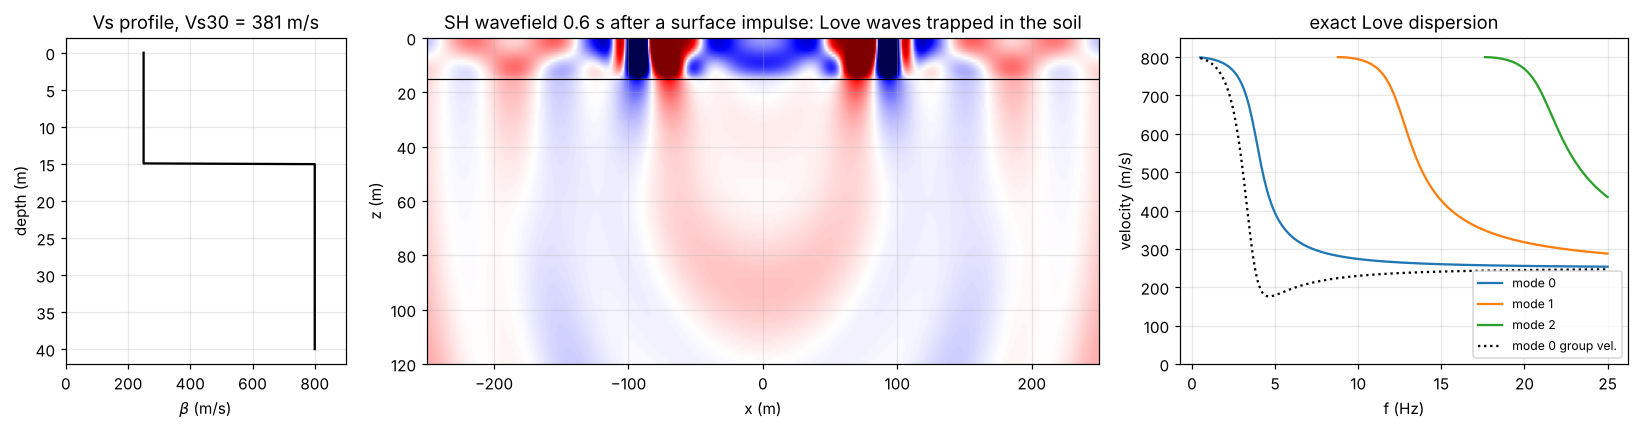

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1, 2.4, 1.6]))
z = np.linspace(0, 40, 400); b, _ = site.profile(z)
ax[0].plot(b, z, "k"); ax[0].invert_yaxis()
ax[0].set(xlabel=r"$\beta$ (m/s)", ylabel="depth (m)", title=f"Vs profile, Vs30 = {v30:.0f} m/s", xlim=(0, 900))
ts = 0.6; snap = ll.snaps[ts]
lim = np.percentile(np.abs(snap), 99.5)
ax[1].imshow(snap, extent=[ll.grid.x[ll.grid.ns], -ll.grid.x[ll.grid.ns], ll.z_snap[-1], 0], cmap="seismic",
             vmin=-lim, vmax=lim, aspect="auto")
ax[1].axhline(site.H, color="k", lw=0.8); ax[1].set(xlim=(-250, 250), ylim=(120, 0), xlabel="x (m)", ylabel="z (m)",
             title=f"SH wavefield {ts} s after a surface impulse: Love waves trapped in the soil")
for n in range(3): ax[2].plot(fs, exact[n], label=f"mode {n}")
ax[2].plot(fs, [L.group_velocity(x, site) for x in fs], "k:", label="mode 0 group vel.")
ax[2].set(xlabel="f (Hz)", ylabel="velocity (m/s)", title="exact Love dispersion", ylim=(0, 850)); ax[2].legend(fontsize=8)
plt.tight_layout()

## 2. Active shot vs passive noise vs exact
Noise sources sit at the surface along the line beyond both ends (out to 150 m, every 2 m), like traffic on a road the survey runs along. The noise gather is the expected cross-correlation of channel 0 with every channel (causal and time-reversed acausal branches stacked), so channel 0 acts as a virtual source. The active reference is a hammer shot 10 m before channel 0.

active  : fundamental pick error 5-12 Hz: mean -0.23 %, max |e| 0.95 %
passive : fundamental pick error 5-12 Hz: mean +0.13 %, max |e| 0.66 %


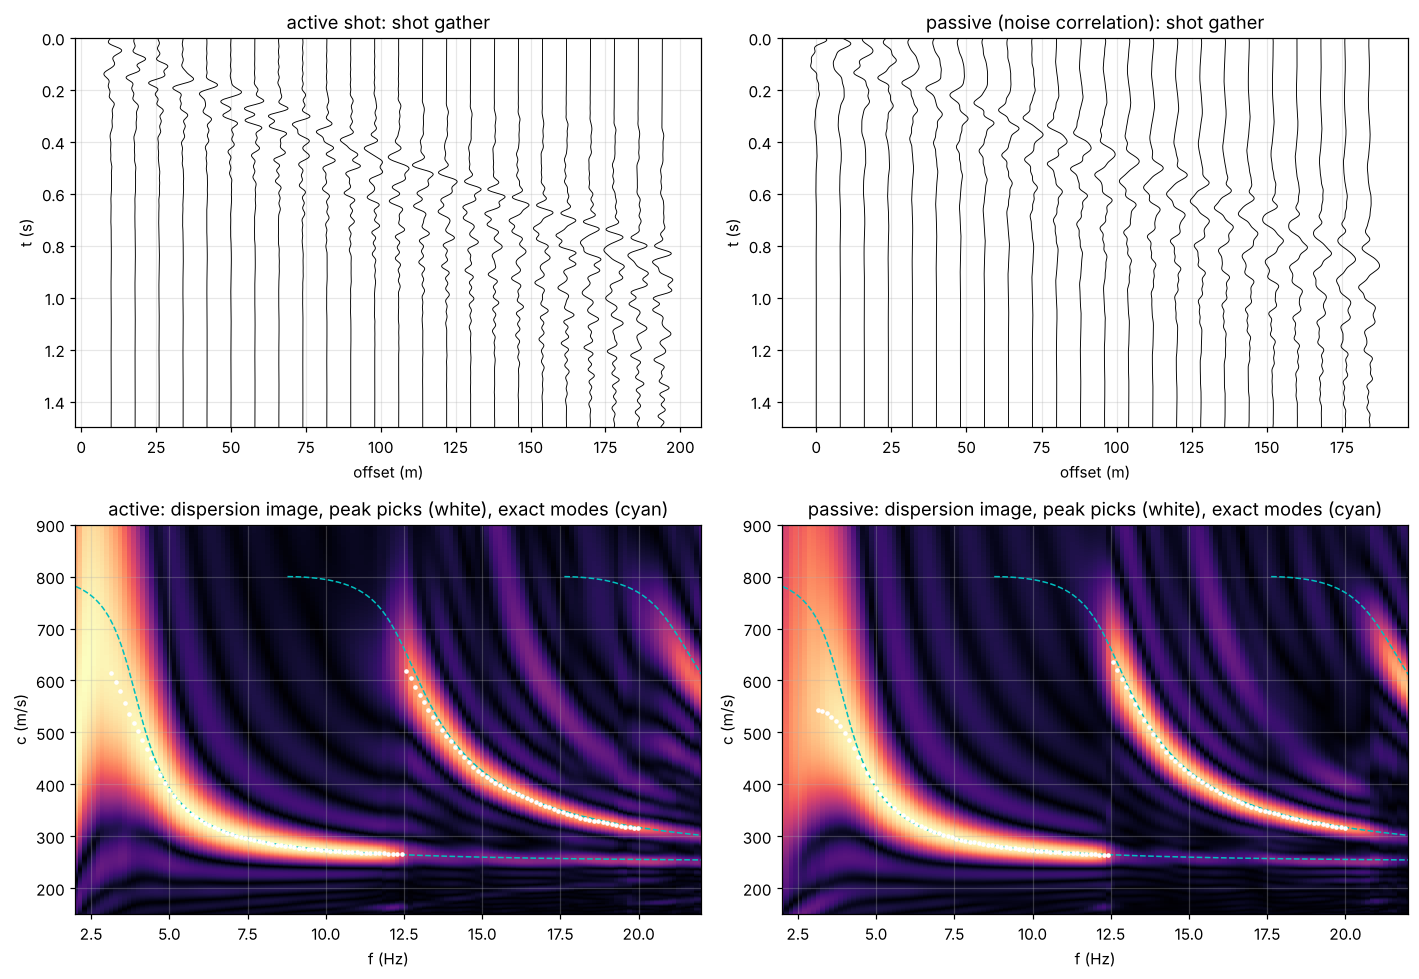

In [3]:
both = L.line_sources("both", rec_x=rx)
U_act = ll.active_gather(rx, rx[0] - 10)
U_pas = ll.noise_gather(rx, both)
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, U, o, name in [(ax[0, 0], U_act, off + 10, "active shot"), (ax[0, 1], U_pas, off, "passive (noise correlation)")]:
    t, tr = ll.to_time(U)
    tr = tr / np.abs(tr).max(axis=0)
    for j in range(0, len(rx), 2):
        a.plot(o[j] + 3.5 * tr[:, j], t, "k", lw=0.6)
    a.set(ylim=(1.5, 0), xlabel="offset (m)", ylabel="t (s)", title=f"{name}: shot gather")
picks = {}
for a, U, o, name in [(ax[1, 0], U_act, off + 10, "active"), (ax[1, 1], U_pas, off, "passive")]:
    img = image(U, o); picks[name] = L.pick_ridge(img, c, ll.f, 3, 20)
    show_image(a, img, f"{name}: dispersion image, peak picks (white), exact modes (cyan)", picks[name])
plt.tight_layout()
for name, (fp, cp) in picks.items():
    e = err(fp, cp); m = (fp >= 5) & (fp <= 12)
    print(f"{name:8s}: fundamental pick error 5-12 Hz: mean {e[m].mean():+.2f} %, max |e| {np.abs(e[m]).max():.2f} %")

The noise-derived gather reproduces the active one: the two dispersion images and picks are nearly identical, and both match the exact fundamental to a few tenths of a percent between 5 and 12 Hz. Two features are physical rather than errors:
* **Low frequencies (< 4 Hz):** the 188 m line is shorter than about one wavelength, so the image ridge is broad and the pick drifts (section 4).
* **Above about 12.6 Hz** the image peak jumps from the fundamental to **mode 1**, because a surface source at this strong-contrast site excites mode 1 more strongly there. A peak picker follows it (section 6).

## 3. Expected correlation vs a finite noise record
The expected correlation assumes infinitely long averaging. With real noise, every source fires with a random spectrum in every time window, and the stacked correlation converges only as more windows are added. Below, each window is a fresh random realisation of all 150 sources firing at once.

    1 windows: RMS error 3.66 %
   10 windows: RMS error 0.73 %
  100 windows: RMS error 0.37 %
 1000 windows: RMS error 0.32 %


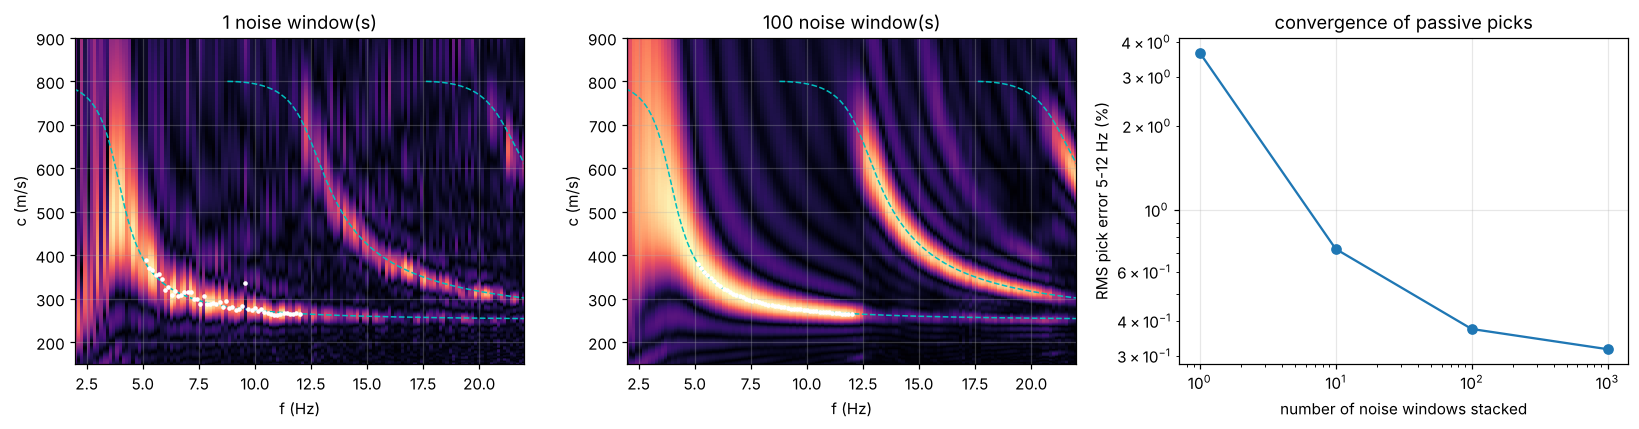

In [4]:
band = (ll.f >= 5) & (ll.f <= 12)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
rms = {}
for k, n in enumerate([1, 10, 100, 1000]):
    U = ll.random_gather(rx, both, n, seed=1)
    img = image(U); fp, cp = L.pick_ridge(img, c, ll.f, 5, 12)
    rms[n] = np.sqrt(np.mean(err(fp, cp) ** 2))
    if n in (1, 100): show_image(ax[k // 2], img, f"{n} noise window(s)", (fp, cp))
ax[2].loglog(list(rms), list(rms.values()), "o-")
ax[2].set(xlabel="number of noise windows stacked", ylabel="RMS pick error 5-12 Hz (%)", title="convergence of passive picks")
plt.tight_layout()
for n, v in rms.items(): print(f"{n:5d} windows: RMS error {v:.2f} %")

A single window already shows the fundamental ridge, because the phase-shift transform stacks 48 channels, but individual picks scatter by several percent. Errors fall roughly as $1/\sqrt{N}$ and reach the expected-correlation result after about 100 windows. The rest of the notebook uses the expected correlation, which isolates **systematic** errors from random ones.

## 4. Array aperture: how long must the line be?
We change the number of channels and the spacing, then measure pick error as a function of wavelength over aperture, $\lambda/L$.

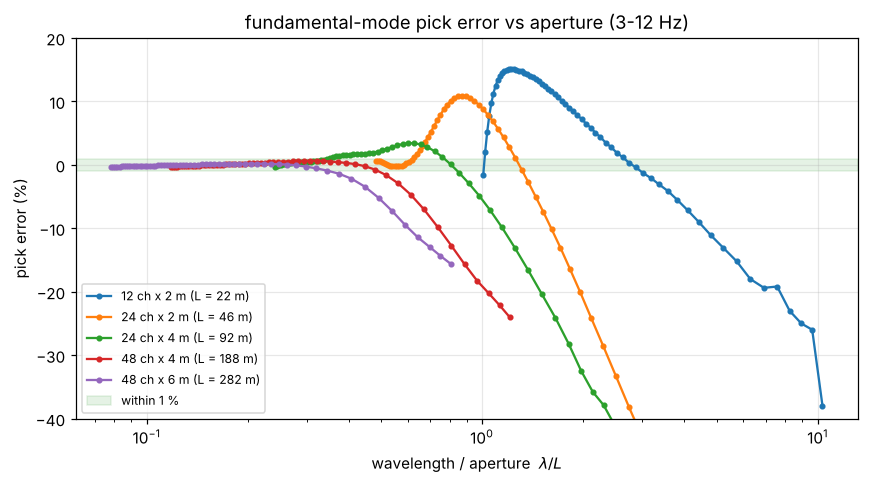

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for n, d in [(12, 2), (24, 2), (24, 4), (48, 4), (48, 6)]:
    r = L.channels(n, d, -90.0); ap = r[-1] - r[0]
    U = ll.noise_gather(r, L.line_sources("both", rec_x=r))
    fp, cp = L.pick_ridge(L.phase_shift(U, r - r[0], ll.f, c), c, ll.f, 3, 12)
    lam = np.array([L.love_root(x, site) for x in fp]) / fp
    ax.plot(lam / ap, err(fp, cp), "o-", ms=3, label=f"{n} ch x {d} m (L = {ap:.0f} m)")
ax.axhspan(-1, 1, color="g", alpha=0.1, label="within 1 %")
ax.set(xscale="log", xlabel=r"wavelength / aperture  $\lambda/L$", ylabel="pick error (%)", ylim=(-40, 20),
       title="fundamental-mode pick error vs aperture (3-12 Hz)"); ax.legend(fontsize=8); plt.tight_layout()

For every line tested, the picks stay within about 1% only for wavelengths shorter than about **a third of the aperture** ($L \gtrsim 3\lambda$). Errors are about 2–5% at $\lambda \approx L/2$ and 10–20% at $\lambda \approx L$, where the low-frequency picks drift *slow*. This is stricter than the "aperture of about one wavelength" rule of thumb. The low frequencies are what sense the bedrock, so a short line under-resolves $\beta_2$. Very short lines (12 channels × 2 m) also show biases of several percent at short wavelengths, from the near field of the virtual source.

## 5. Where the noise comes from
* **In-line, one side only** (left or right): the folded correlation (causal + time-reversed acausal) still has a stationary-phase source behind one end of every pair.
* **Everywhere along the line**, including under the array.
* **Off-line**: far sources whose waves cross the line at angle $\theta$, for example a road at an angle to the survey. The along-line apparent speed is $c/\cos\theta$, the same azimuth–velocity ambiguity as in the DAS study.
* **A spread of azimuths**, uniform over $0$–$\theta_{max}$ from both ends.

in-line, left only    : mean error 5-12 Hz  +0.1 %
in-line, right only   : mean error 5-12 Hz  +0.1 %
in-line, everywhere   : mean error 5-12 Hz  +0.0 %
off-line, θ = 20°     : mean error 5-12 Hz  +6.6 %
off-line, θ = 40°     : mean error 5-12 Hz +30.9 %
azimuth spread 0-30°  : mean error 5-12 Hz  +2.5 %
azimuth spread 0-90°  : mean error 5-12 Hz  +0.9 %


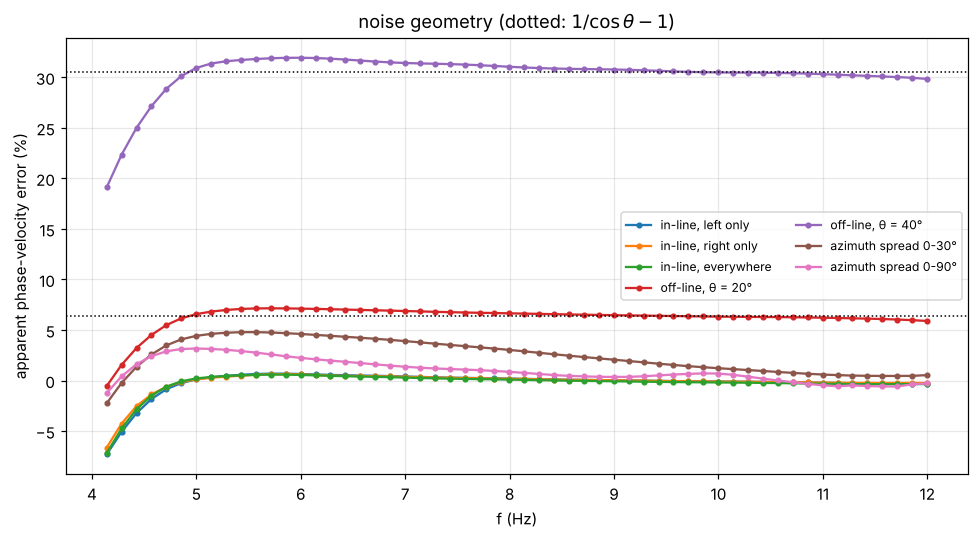

In [6]:
def spread(th_max, n=10):
    parts = [L.line_sources("offline", theta_deg=d, rec_x=rx) for d in np.linspace(0, th_max, n)]
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
cases = {"in-line, left only": L.line_sources("left", rec_x=rx), "in-line, right only": L.line_sources("right", rec_x=rx),
         "in-line, everywhere": L.line_sources("everywhere", rec_x=rx)}
cases.update({f"off-line, θ = {d}°": L.line_sources("offline", theta_deg=d, rec_x=rx) for d in (20, 40)})
cases.update({"azimuth spread 0-30°": spread(30), "azimuth spread 0-90°": spread(90)})
fig, ax = plt.subplots(figsize=(9, 5))
geo = {}
for name, src in cases.items():
    fp, cp = L.pick_ridge(image(ll.noise_gather(rx, src)), c, ll.f, 4, 12)
    geo[name] = err(fp, cp); ax.plot(fp, geo[name], "o-", ms=3, label=name)
for d in (20, 40): ax.axhline(100 * (1 / np.cos(np.radians(d)) - 1), color="k", ls=":", lw=1)
ax.set(xlabel="f (Hz)", ylabel="apparent phase-velocity error (%)", title=r"noise geometry (dotted: $1/\cos\theta - 1$)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
for name, e in geo.items(): print(f"{name:22s}: mean error 5-12 Hz {e[(fp >= 5)].mean():+5.1f} %")

* **One-sided in-line noise is harmless** here. With the acausal branch folded in, either side supplies the stationary-phase sources, and sources under the array do no harm either. In this 2D (in-plane) setting the directional failure is *not* one-sidedness.
* **Off-line noise is the real problem.** A single off-line direction biases the curve fast by exactly $1/\cos\theta - 1$ (6% at 20°, 31% at 40°), and a straight line cannot detect this, as with DAS. A spread of azimuths biases the peak fast by a few percent at 5–8 Hz, because the image ridge smears toward high $c$. This is why ReMi (Louie 2001) picks the *lower envelope* of the slowness image rather than its peak.

## 6. Mode contamination: source depth and velocity contrast
How the energy splits between modes depends on how deep the sources are and on the impedance contrast. The global-maximum picker follows the strongest mode.

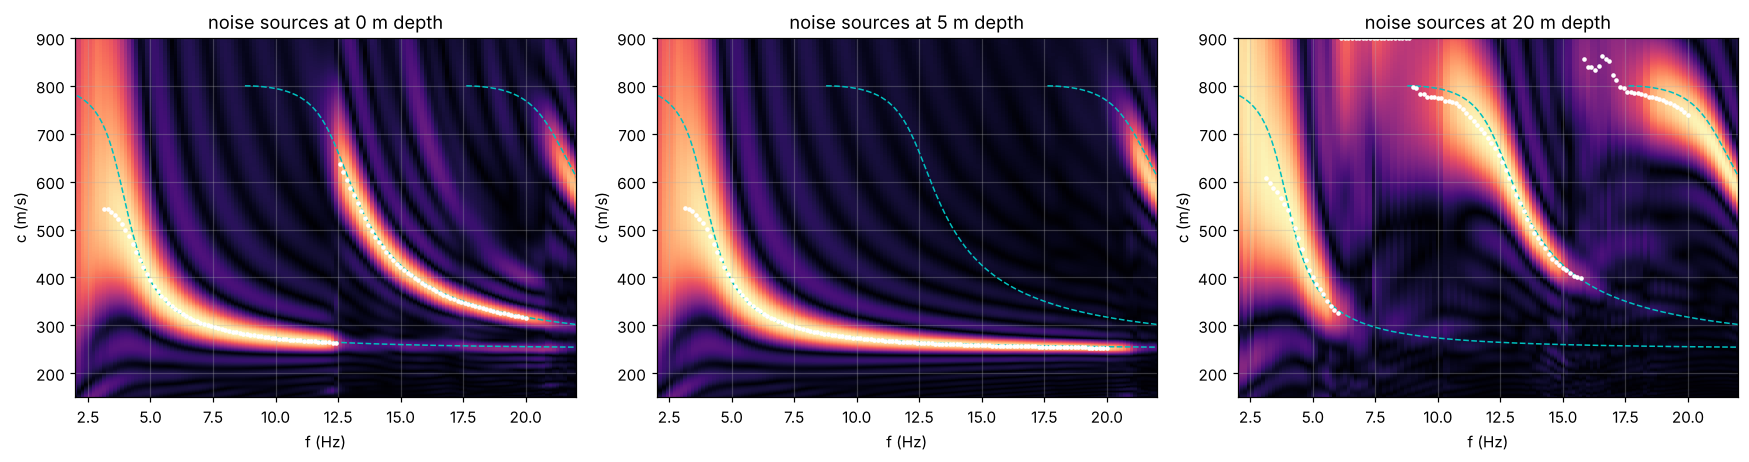

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, di in zip(ax, [0, 3, 5]):
    img = image(ll.noise_gather(rx, L.line_sources("both", depth_index=di, rec_x=rx)))
    show_image(a, img, f"noise sources at {L.SOURCE_DEPTHS[di]:.0f} m depth", L.pick_ridge(img, c, ll.f, 3, 20))
plt.tight_layout()

* **Surface sources (0 m):** the peak jumps to mode 1 above about 12.6 Hz.
* **5 m deep:** the fundamental dominates up to 20 Hz. The depth is close to a node of the mode-1 eigenfunction, so mode 1 is barely excited.
* **20 m deep (in the bedrock):** most of the energy is in leaky and body waves faster than $\beta_2$, and the low-velocity fundamental is weak above about 7 Hz.

The same comparison for a **weaker contrast** ($\beta_2 = 500$ m/s, one more FD run): the mode-1 cutoff moves up to 9.6 Hz and the jump moves to about 14 Hz, but it does not go away.

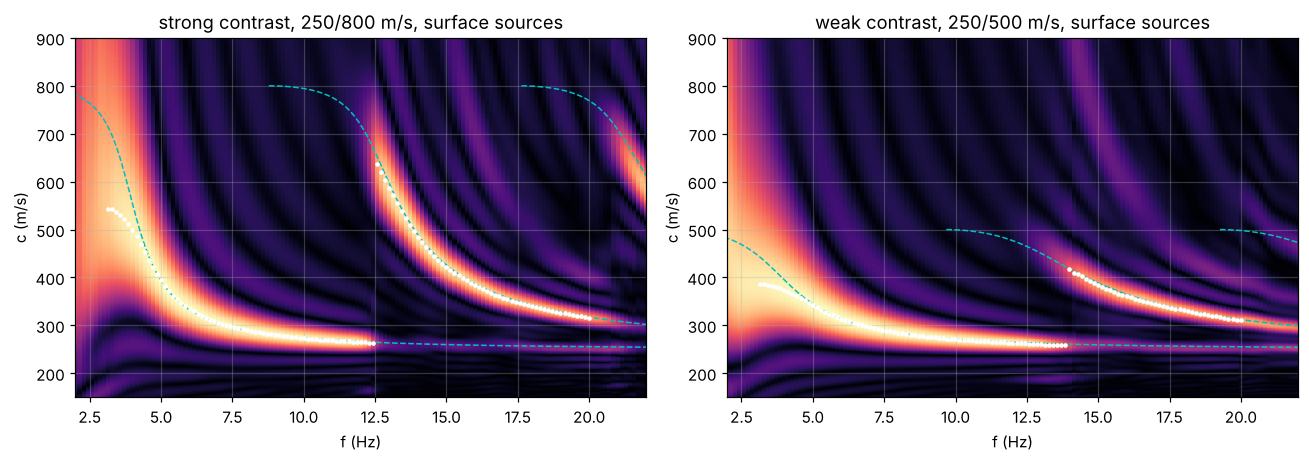

In [8]:
weak = L.Site(b2=500.0)
llw = L.LoveLine(weak)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for a, (lx, st, name) in zip(ax, [(ll, site, "strong contrast, 250/800 m/s"), (llw, weak, "weak contrast, 250/500 m/s")]):
    U = lx.noise_gather(rx, L.line_sources("both", rec_x=rx))
    img = L.phase_shift(U, off, lx.f, c)
    a.pcolormesh(lx.f, c, img.T, cmap="magma", shading="auto", vmin=0, vmax=1)
    for n in range(3): a.plot(fs, L.love_modes(fs, st, 3)[n], "c--", lw=1)
    a.plot(*L.pick_ridge(img, c, lx.f, 3, 20), "w.", ms=4)
    a.set(xlim=(2, 22), ylim=(150, 900), xlabel="f (Hz)", ylabel="c (m/s)", title=f"{name}, surface sources")
plt.tight_layout()

## 7. From picks to Vs30 and site class
We invert each picked curve for $(\beta_1, H, \beta_2)$ by damped Gauss–Newton, with the exact root finder as the forward model and the assumption that the picks are the fundamental. Picks come from 4–20 Hz. We compare:
* the global-maximum picker vs a **ridge-tracking** picker (follow the fundamental upward from 4 Hz, within ±10%), and
* clean noise vs off-line noise.

| scenario | β₁ (m/s) | H (m) | β₂ (m/s) | misfit (m/s) | Vs30 (m/s) | Vs30 error | NEHRP class |
|---|---|---|---|---|---|---|---|
| **true model** | 250 | 15.0 | 800 | 0.0 | 381 | +0.0 % | C (very dense soil) |
| surface sources, peak picks | 353 | 67.9 | 3000 | 87.8 | 353 | -7.5 % | D (stiff soil) |
| surface sources, tracked picks | 247 | 13.9 | 653 | 1.5 | 370 | -2.9 % | C (very dense soil) |
| 5 m deep sources, peak picks | 248 | 14.1 | 662 | 0.5 | 371 | -2.7 % | C (very dense soil) |
| off-line 20°, tracked picks | 262 | 14.8 | 693 | 2.0 | 383 | +0.6 % | C (very dense soil) |
| off-line 40°, tracked picks | 321 | 17.7 | 808 | 2.9 | 426 | +11.8 % | C (very dense soil) |
| azimuth spread 0-30°, tracked | 248 | 13.3 | 645 | 2.2 | 377 | -1.2 % | C (very dense soil) |

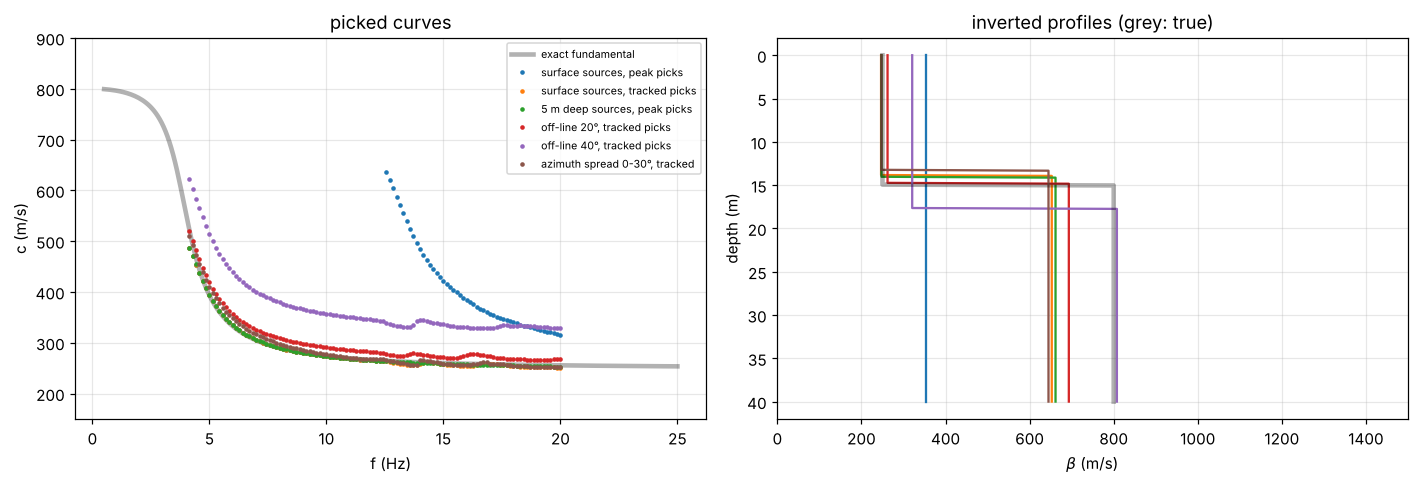

In [9]:
scen = {"surface sources, peak picks": (L.line_sources("both", rec_x=rx), False),
        "surface sources, tracked picks": (L.line_sources("both", rec_x=rx), True),
        "5 m deep sources, peak picks": (L.line_sources("both", depth_index=3, rec_x=rx), False),
        "off-line 20°, tracked picks": (L.line_sources("offline", theta_deg=20, rec_x=rx), True),
        "off-line 40°, tracked picks": (L.line_sources("offline", theta_deg=40, rec_x=rx), True),
        "azimuth spread 0-30°, tracked": (spread(30), True)}
rows = [("**true model**", site.b1, site.H, site.b2, 0.0, v30)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(fs, exact[0], "k", lw=3, alpha=0.3, label="exact fundamental")
for name, (src, track) in scen.items():
    fp, cp = L.pick_ridge(image(ll.noise_gather(rx, src)), c, ll.f, 4, 20, track=track)
    p, misfit = L.invert_site(fp, cp)
    rows.append((name, *p, misfit, L.vs30(*p)))
    l, = ax[0].plot(fp, cp, ".", ms=4, label=name)
    zz = np.linspace(0, 40, 400); ax[1].plot(L.Site(p[0], p[2], p[1]).profile(zz)[0], zz, color=l.get_color())
ax[1].plot(site.profile(zz)[0], zz, "k", lw=3, alpha=0.3)
ax[0].set(xlabel="f (Hz)", ylabel="c (m/s)", title="picked curves", ylim=(150, 900)); ax[0].legend(fontsize=7)
ax[1].invert_yaxis(); ax[1].set(xlabel=r"$\beta$ (m/s)", ylabel="depth (m)", title="inverted profiles (grey: true)", xlim=(0, 1500))
plt.tight_layout()
from IPython.display import Markdown
Markdown("| scenario | β₁ (m/s) | H (m) | β₂ (m/s) | misfit (m/s) | Vs30 (m/s) | Vs30 error | NEHRP class |\n|---|---|---|---|---|---|---|---|\n" +
         "\n".join(f"| {n} | {b1:.0f} | {H:.1f} | {b2:.0f} | {m:.1f} | {v:.0f} | {100 * (v / v30 - 1):+.1f} % | {L.site_class(v)} |"
                   for n, b1, H, b2, m, v in rows))

* **Clean picks** (tracked, or from 5 m deep sources) recover the soil layer to within about 1–6%. $\beta_2$ comes out low because the 188 m line cannot pick the fundamental below 4 Hz, where the curve senses the bedrock (section 4). Vs30 is still within about 3%, which is why Vs30 is a robust summary.
* **Mode mispicks** are the most damaging failure. The jumped picks cannot be fitted by a fundamental mode: the misfit is about 90 m/s, which is a clear warning sign. The best-fitting model is meaningless, and Vs30 drops to class **D** while the true site is class **C**. Tracking the ridge fixes it.
* **Off-line noise** biases every pick fast, and the inversion fits the biased curve well. The misfit stays low, so there is no warning. At 20° the soil speed comes out 5% fast and Vs30 rises about 3% relative to the clean-noise inversion. At 40° the soil speed comes out 30% fast (about $1/\cos 40°$) and Vs30 12% high. The class happens not to change here, but at a site near a class boundary (360 or 760 m/s) it would. A straight line cannot detect this from the data alone.

## 8. Model sweep (exact curves)
How the layer thickness and the contrast move the dispersion curve and the mode cutoffs. These curves are what the inversion matches, and what the app's sliders change.

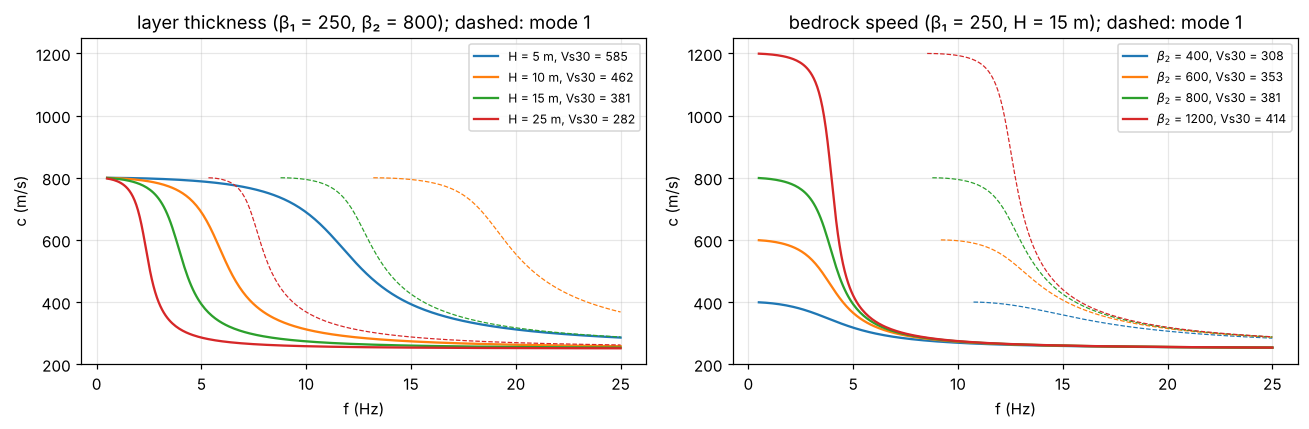

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for H in [5, 10, 15, 25]:
    s = L.Site(H=H); ax[0].plot(fs, L.love_modes(fs, s, 2)[0], label=f"H = {H} m, Vs30 = {L.vs30(s.b1, H, s.b2):.0f}")
    ax[0].plot(fs, L.love_modes(fs, s, 2)[1], "--", color=ax[0].lines[-1].get_color(), lw=0.8)
for b2 in [400, 600, 800, 1200]:
    s = L.Site(b2=b2); ax[1].plot(fs, L.love_modes(fs, s, 2)[0], label=rf"$\beta_2$ = {b2}, Vs30 = {L.vs30(s.b1, s.H, b2):.0f}")
    ax[1].plot(fs, L.love_modes(fs, s, 2)[1], "--", color=ax[1].lines[-1].get_color(), lw=0.8)
for a, t in zip(ax, ["layer thickness (β₁ = 250, β₂ = 800)", "bedrock speed (β₁ = 250, H = 15 m)"]):
    a.set(xlabel="f (Hz)", ylabel="c (m/s)", title=t + "; dashed: mode 1", ylim=(200, 1250)); a.legend(fontsize=8)
plt.tight_layout()

## Summary
* Ambient-noise correlations along a surface line reproduce the active-shot dispersion image, and the FD chain matches the exact Love-wave fundamental to a few tenths of a percent wherever the array can resolve it.
* **Aperture:** picks are reliable for $\lambda \lesssim L/2$. Short lines lose the low frequencies and with them the bedrock speed. Vs30 is less sensitive.
* **Noise direction:** one-sided noise along the line is harmless once both branches are folded. Off-line noise is not: it biases the curve fast by $1/\cos\theta$ with a low misfit, so the error is invisible, and Vs30 is too high.
* **Mode contamination:** at a strong-contrast site, surface sources put mode 1 above the fundamental at high frequency. A peak picker jumps modes, and the inversion then misclassifies the site (C → D here). Ridge tracking and a misfit check catch it.